In [1]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import pandas as pd
from joblib import load
from sklearn.ensemble import GradientBoostingClassifier

# Load your data
data = pd.read_csv(r'train.csv')

# Check the columns
#print(data.columns)

# Ensure the target column name is correct
target_column_name = 'fake'  # Replace with actual name after checking

# Split the features and target
X = data.drop(target_column_name, axis=1)
y = data[target_column_name]

# Splitting the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

gb = GradientBoostingClassifier()
gb.fit(X_train, y_train)

# Sample code snippet for prediction and evaluation
gb_y_pred = gb.predict(X_test)  # Make predictions on the test set
gb_accuracy = accuracy_score(y_test, gb_y_pred)  # Accuracy calculation on the correct labels
print("Accuracy:", gb_accuracy)

gb_precision = precision_score(y_test, gb_y_pred)
print("Precision:", gb_precision)

gb_recall = recall_score(y_test, gb_y_pred)
print("Recall:", gb_recall)

gb_f1_score = f1_score(y_test, gb_y_pred)
print("F1-score:", gb_f1_score)

gb_classification_report = classification_report(y_test, gb_y_pred)
print("Classification Report:")
print(gb_classification_report)

Accuracy: 0.9051724137931034
Precision: 0.9375
Recall: 0.8490566037735849
F1-score: 0.8910891089108911
Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.95      0.92        63
           1       0.94      0.85      0.89        53

    accuracy                           0.91       116
   macro avg       0.91      0.90      0.90       116
weighted avg       0.91      0.91      0.90       116



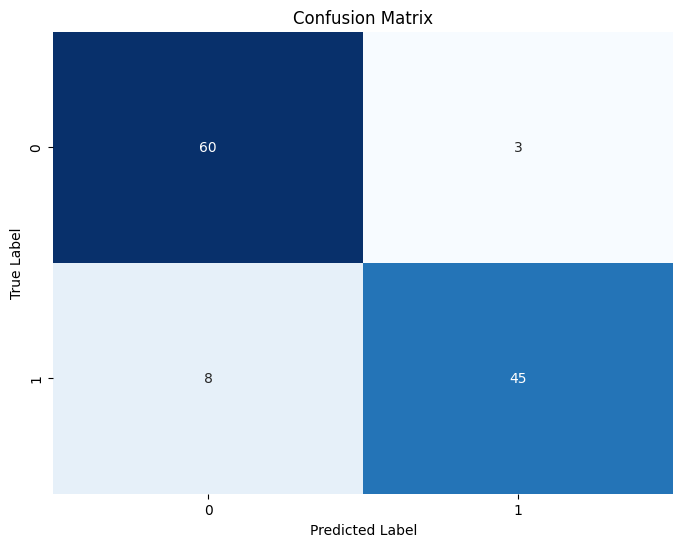

In [2]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

conf_matrix = confusion_matrix(y_test, gb_y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


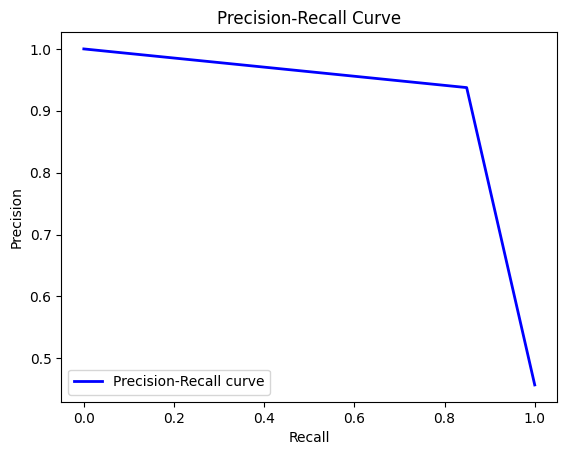

In [3]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(y_test, gb_y_pred)

plt.figure()
plt.plot(recall, precision, color='blue', lw=2, label='Precision-Recall curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()